In [1]:
#Importing the necessary libraries and filtering the warnings
from plextract import extract 
import pandas as pd
import json 
import numpy as np 
from scipy.stats import norm


from utilsforecast.evaluation import evaluate
from utilsforecast.losses import *
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA
from utilsforecast.plotting import plot_series

import warnings 
warnings.filterwarnings("ignore")

/mnt/c/Users/solon/Desktop/Time series extraction/extract-line-chart-data/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Using the extract command from the "extract-line-chart-data" git hub repo to extract the points of the plot.
extract(input_dir="/mnt/c/Users/solon/Desktop/Time series extraction/Test/Test_image", output_dir="/mnt/c/Users/solon/Desktop/Time series extraction/Test/Test_output", backend="local")

2026-10-26 18:00:15,221 | INFO | plextract | Running plextract locally...
2026-10-26 18:00:19,507 | INFO | plextract | Running local pipeline...
2026-10-26 18:00:19,508 | INFO | plextract |   Input: /mnt/c/Users/solon/Desktop/Time series extraction/Test/Test_image
2026-10-26 18:00:19,509 | INFO | plextract |   Output: /mnt/c/Users/solon/Desktop/Time series extraction/Test/Test_output
2026-10-26 18:00:19,514 | INFO | plextract | Creating output folders...
2026-10-26 18:00:19,528 | INFO | plextract | Extracting lines from images using LineFormer...


load checkpoint from local path: /home/psaronefri/.cache/plextract/lineformer/iter_3000.pth
load checkpoint from local path: /home/psaronefri/.cache/plextract/chartdete/checkpoint.pth


Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


	Correcting coordinates for: /mnt/c/Users/solon/Desktop/Time series extraction/Test/Test_output Screenshot 2026-10-26 180736.png
	Now starting to sort and check labels...
Sorting coordinates...
Calculating conversions now...
Converting data points now...


In [3]:
#Opening the json file that contains the values in coordinates.
#This code is hardcoded due to lack of time, but it can be dynamically coded with the os module.
with open("/mnt/c/Users/solon/Desktop/Time series extraction/Test/Test_output/Screenshot 2026-10-26 180736.png/converted_datapoints/data.json" , "r") as file :
    raw_data = json.load(file)

#Making the data frame to store the values.
df = pd.DataFrame(raw_data["series_0"])
df["x"] = df["x"].astype(float)
df["y"] = df["y"].astype(float)

#The json file contains all the dots that make the graph in coordinates. This much data will conflict with the ARIMA model that we plan on using.
#To avoid these conflicts we discretize our data by calculating the mean y-value for each integer time step.

#Starting off we save the minimum and maximum values for x and y.
x_pixel_min, x_pixel_max = df['x'].min(), df['x'].max()
y_pixel_min, y_pixel_max = df['y'].min(), df['y'].max()

#We type out the true minimum and maximum values of the x and y variables. We know these values by looking at the graph.
#This part is hardcoded due to lack of time. It can be dynamically coded because we have a json file with these exact values.
x_real_min, x_real_max = 1.0, 60.0 
y_real_min, y_real_max = 310.0, 400.0  

# Min-Max scaling.
#Changing the coordinates of the pixels that make the line so that they have the same scale as the graph 
df['x_real'] = x_real_min + (df['x'] - x_pixel_min) * (x_real_max - x_real_min) / (x_pixel_max - x_pixel_min)
df['y_real'] = y_real_min + (df['y'] - y_pixel_min) * (y_real_max - y_real_min) / (y_pixel_max - y_pixel_min)

#Downsampling the pixels that make the graph to only the points needed.
df['x_real'] = df['x_real'].round().astype(int)
clean_df = df.groupby('x_real')['y_real'].mean().reset_index()

#Cleaning the data so that we can continue our analysis.
clean_df = clean_df.rename(columns={'x_real': 'ds', 'y_real': 'y'})
clean_df.insert(0, 'unique_id', 'Series_0')

print(clean_df.head())


  unique_id  ds           y
0  Series_0   1  313.701299
1  Series_0   2  311.363636
2  Series_0   3  312.142857
3  Series_0   4  316.038961
4  Series_0   5  319.935065


In [4]:
#Specifying the ARIMA model.
model = [AutoARIMA(seasonal= False , alias= "Arima")]


#Using the StatsForecast function.
sf = StatsForecast(models = model , freq = 1)

#Setting the rolling forecast step to 3.
horizon = 3

#Using the cross_validation function. This function by default applies rolling forecast.
cv_df = sf.cross_validation(

    h = horizon,

    #Specifying our data set.
    df = clean_df, 

    #Specifying the number of windows that the rolling forecast will be applied.
    n_windows= horizon % len(clean_df), 

    #Setting the step size the same as the horizon so that our values don't overlap. 
    step_size = horizon,

    #Refitting in every recursive step.  
    refit = True,

    #Setting a level for the confidence interval.  
    level = [95]
)

cv_df.head()

,unique_id,ds,cutoff,y,Arima,Arima-lo-95,Arima-hi-95
0,Series_0,52,51,364.301948,365.291352,358.651684,371.931021
1,Series_0,53,51,374.090909,375.060139,361.467107,388.653172
2,Series_0,54,51,381.152597,381.266296,364.076691,398.455902
3,Series_0,55,54,384.192950,381.894779,375.201966,388.587592
4,Series_0,56,54,385.487013,378.613030,364.041708,393.184352


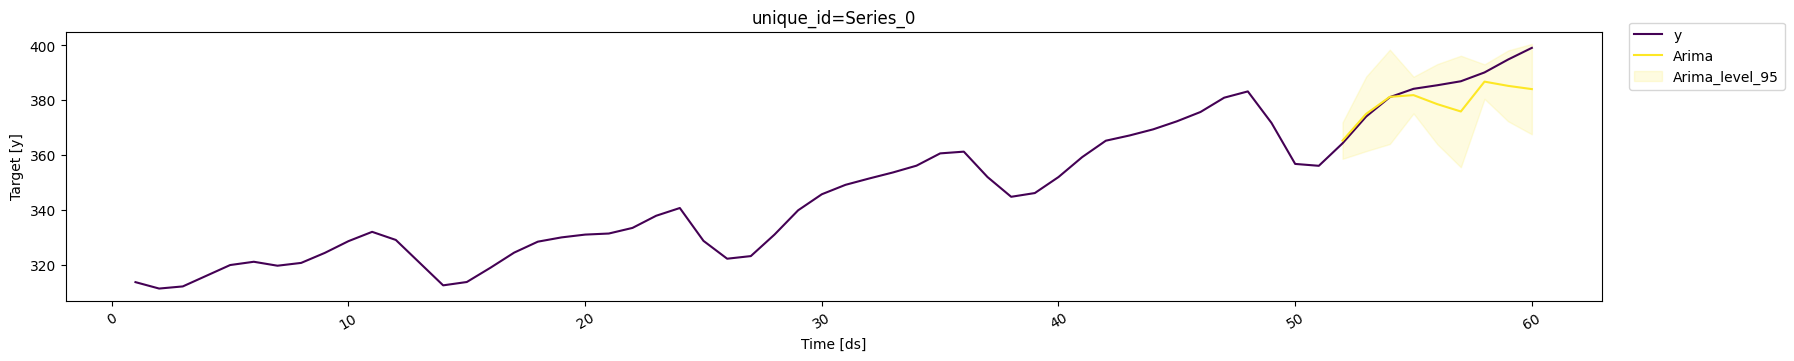

In [5]:
#Plotting the graph and our predictions. 
plot_series(
    df=clean_df, 
    forecasts_df=cv_df.drop(["y", "cutoff"], axis=1), 
    ids=["Series_0"], 
    max_insample_length=140, 
    palette="viridis",
    level = [95])

In [6]:
#Setting the evaluation metric. We will be using smape so that we can pinpoint the possibility that our next prediction is false.
final_eval = evaluate(

    #Specifying the dataframe.
    df = cv_df.drop("cutoff" , axis = 1),

    #Specifying the metric.
    metrics = [smape],

    #Specifying the model that we used based on the alias.
    models = ["Arima"],

    #Specifying the level of our confidence interval for the smape metrics.
    level = [95]
)

final_eval.head()

,unique_id,metric,Arima
0,Series_0,smape,0.007232


In [7]:
#Adding an error column to the dataframe 
cv_df['error'] = np.abs(cv_df['y'] - cv_df['Arima'])/np.abs(cv_df["y"])

#Calculating the mean of the errors
mean_err = cv_df['error'].mean()

#Calculating the standard deviation
std_err = cv_df['error'].std()

#Setting the threshold as the smape evaluation 
threshold = final_eval["Arima"]  

#Getting the probability for our next point to be incorrect via the norm.cdf function from scipy.stats library.
probability_incorrect = 1 - norm.cdf(threshold, loc=mean_err, scale=std_err)

print(probability_incorrect)

[0.70095487]
